# One-stage anchor-based detector: RetinaNet ResNet-50 FPN
Here the results of RetinaNet ResNet-50 FPN experiments and model checks.

We use RetinaNet with COCO-pretrained weights, replace the output layer to support 8 classes, add ignore-region handling during training, and apply the same inference settings as Faster R-CNN (score ≥ 0.01, maximum 500 detections).

In [ ]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)

In [ ]:
TASK_DIR = Path('.').resolve()
ANALYSIS_DIR = TASK_DIR / 'anchor_analysis'
ROOT = TASK_DIR.parent
METRICS = ['mAP', 'AP50', 'AP75', 'APs', 'APm', 'APl', 'AR']

## Object sizes and anchor coverage

In [ ]:
box_sizes = pd.read_csv(ANALYSIS_DIR / 'box_sizes.csv')
size_columns = ['group', 'n', 'share', 'side_p5', 'side_p25', 'side_p50', 'side_p75', 'side_p95', 'ratio_p10', 'ratio_p50', 'ratio_p90']
display(box_sizes[size_columns].round(2))

,group,n,share,side_p5,side_p25,side_p50,side_p75,side_p95,ratio_p10,ratio_p50,ratio_p90
0,all,222879,1.00,14.13,22.46,31.62,45.63,87.00,0.47,1.06,2.26
1,class bicycle,8129,0.04,13.29,20.11,26.30,35.52,51.64,0.57,1.05,1.95
2,class bus,1945,0.01,22.13,43.85,72.32,113.43,185.31,0.34,0.97,1.60
3,class car,101814,0.46,16.13,26.13,37.39,54.97,95.83,0.41,0.80,1.22
4,class motor,20712,0.09,13.65,20.04,26.68,35.56,53.24,0.64,1.24,1.96
5,class person,66353,0.30,11.57,18.79,25.57,34.30,52.06,1.32,2.00,2.73
6,class tricycle,8337,0.04,16.13,27.93,39.98,55.44,91.58,0.54,0.94,1.48
7,class truck,6137,0.03,21.60,33.00,51.43,76.69,147.39,0.45,0.93,1.29
8,class van,9452,0.04,17.18,27.29,35.31,53.53,98.49,0.51,0.90,1.40
9,size large,7870,0.04,97.37,103.15,115.68,139.91,187.92,0.42,0.73,1.45


In [ ]:
display(pd.read_csv(ANALYSIS_DIR / 'anchor_coverage.csv').round(3))

,config,objects,n,covered_iou50,mean_best_iou,mean_pos_anchors,zero_pos_share
0,"default (baseline, tuned_focal_loss)",all,222879,0.744,0.622,14.411,0.256
1,"default (baseline, tuned_focal_loss)",small,113572,0.498,0.483,3.330,0.502
2,"default (baseline, tuned_focal_loss)",medium,101437,0.999,0.766,25.638,0.001
3,"default (baseline, tuned_focal_loss)",large,7870,0.997,0.774,29.606,0.003
4,tuned_anchors (0.5x),all,222879,0.957,0.662,6.456,0.043
5,tuned_anchors (0.5x),small,113572,0.921,0.652,6.019,0.079
6,tuned_anchors (0.5x),medium,101437,0.995,0.671,6.870,0.005
7,tuned_anchors (0.5x),large,7870,0.992,0.689,7.427,0.008
8,anchor_intermediate_075 (0.75x),all,222879,0.891,0.676,11.375,0.109
9,anchor_intermediate_075 (0.75x),small,113572,0.786,0.613,6.673,0.214


In [ ]:
anchor_scan = pd.read_csv(ANALYSIS_DIR / 'anchor_scan.csv')
coverage_table = anchor_scan.pivot_table(index=['mult', 'ratios'], columns='objects', values='covered_iou50')
display(coverage_table[['all', 'small', 'medium', 'large']].round(3))

objects                all  small  medium  large
mult ratios                                     
0.35 0.33,0.5,1,2,3  0.856  0.811   0.905  0.866
     0.5,1,2         0.843  0.794   0.896  0.858
     0.5,1,2,3       0.851  0.807   0.899  0.859
0.40 0.33,0.5,1,2,3  0.930  0.904   0.958  0.956
     0.5,1,2         0.921  0.893   0.951  0.949
     0.5,1,2,3       0.926  0.900   0.953  0.950
0.50 0.33,0.5,1,2,3  0.958  0.923   0.996  0.995
     0.5,1,2         0.957  0.921   0.995  0.992
     0.5,1,2,3       0.958  0.922   0.995  0.992
0.60 0.33,0.5,1,2,3  0.943  0.888   1.000  1.000
     0.5,1,2         0.941  0.885   0.999  0.996
     0.5,1,2,3       0.943  0.888   0.999  0.996
0.65 0.33,0.5,1,2,3  0.937  0.876   1.000  1.000
     0.5,1,2         0.936  0.875   0.999  0.996
     0.5,1,2,3       0.936  0.876   1.000  0.996
0.75 0.33,0.5,1,2,3  0.891  0.787   1.000  1.000
     0.5,1,2         0.891  0.786   0.999  0.996
     0.5,1,2,3       0.891  0.786   1.000  0.996
0.85 0.33,0.5,1,2,3  0.829  0.664   1.000  1.000
     0.5,1,2         0.825  0.658   0.999  0.997
     0.5,1,2,3       0.827  0.662   0.999  0.997
1.00 0.33,0.5,1,2,3  0.745  0.500   1.000  1.000
     0.5,1,2         0.744  0.498   0.999  0.997
     0.5,1,2,3       0.745  0.499   0.999  0.997

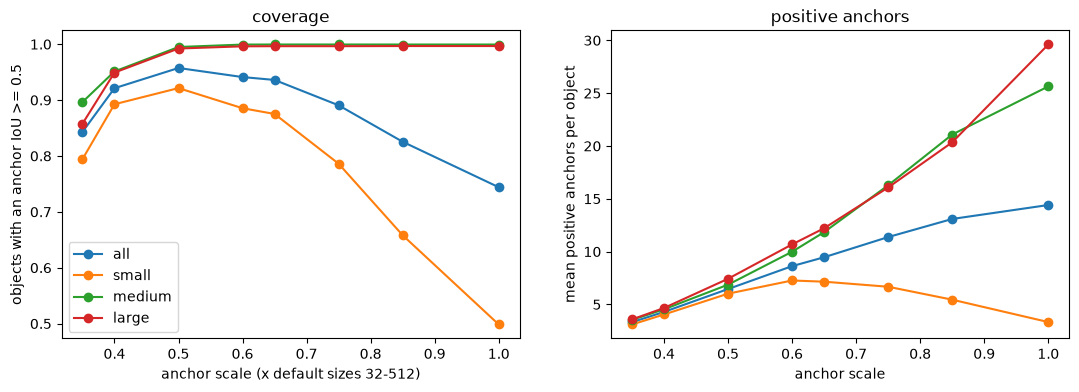

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for group in ['all', 'small', 'medium', 'large']:
    rows = anchor_scan[(anchor_scan.objects == group) & (anchor_scan.ratios == '0.5,1,2')]
    axes[0].plot(rows.mult, rows.covered_iou50, marker='o', label=group)
    axes[1].plot(rows.mult, rows.mean_pos_anchors, marker='o', label=group)
axes[0].set(xlabel='anchor scale (x default sizes 32-512)', ylabel='objects with an anchor IoU >= 0.5', title='coverage')
axes[1].set(xlabel='anchor scale', ylabel='mean positive anchors per object', title='positive anchors')
axes[0].legend()
plt.show()

To select the anchors, we choose the scale that covers the most objects overall while keeping at least 99% coverage of medium and large objects. Based on this criterion, **`anchors_x0.5`** gave the best result, with the default anchor sizes reduced by half.

We also test **`anchors_x0.5_ratios5`** with the same scale but additional aspect ratios of 1/3 and 3, since many objects, especially people, have an elongated shape.

## Screening on fold 0

In [ ]:
screening = json.loads((TASK_DIR / 'screening.json').read_text())
display(pd.DataFrame(screening['decisions']))
print('final configuration:', screening['final']['name'])

,stage,base,base_fold0,candidates,adopted
0,anchors,baseline,0.207018,"{'anchors_x0.5': 0.19998096027842308, 'anchors...",None
1,focal,baseline,0.207018,{'focal_a0.5_g1.5': 0.2054136430559252},None
2,iou,baseline,0.207018,{'iou_0.4_0.3': 0.175709082688909},None


final configuration: baseline


In [ ]:
run_names = sorted(p.name for p in (TASK_DIR / 'runs').iterdir() if (p / 'fold0/result.json').exists())
fold0_results = {name: json.loads((TASK_DIR / 'runs' / name / 'fold0/result.json').read_text()) for name in run_names}
fold0_table = pd.DataFrame({name: {**{m: r['metrics'][m] for m in METRICS}, 'best_epoch': r['best_epoch']}
                            for name, r in fold0_results.items()}).T
display(fold0_table.round(4))

,mAP,AP50,AP75,APs,APm,APl,AR,best_epoch
anchors_x0.5,0.2000,0.3988,0.1782,0.1011,0.1713,0.3142,0.3754,6.0
anchors_x0.5_ratios5,0.2061,0.4003,0.1915,0.1175,0.1792,0.3328,0.3749,6.0
baseline,0.2070,0.3838,0.2061,0.0914,0.1733,0.3212,0.3413,6.0
focal_a0.5_g1.5,0.2054,0.3978,0.1859,0.0916,0.1703,0.3151,0.3535,4.0
iou_0.4_0.3,0.1757,0.3299,0.1730,0.0664,0.1342,0.2834,0.2951,4.0


,anchors_x0.5,anchors_x0.5_ratios5,baseline,focal_a0.5_g1.5,iou_0.4_0.3
epoch,,,,,
1,0.1434,0.1525,0.1997,0.2009,0.1532
2,0.1707,0.1929,0.1960,0.1885,0.1609
3,0.1654,0.1835,0.1700,0.1972,0.1622
4,0.1739,0.1986,0.1834,0.2054,0.1757
5,0.1680,0.1931,0.1969,0.1851,0.1626
6,0.2000,0.2061,0.2070,0.1992,0.1680


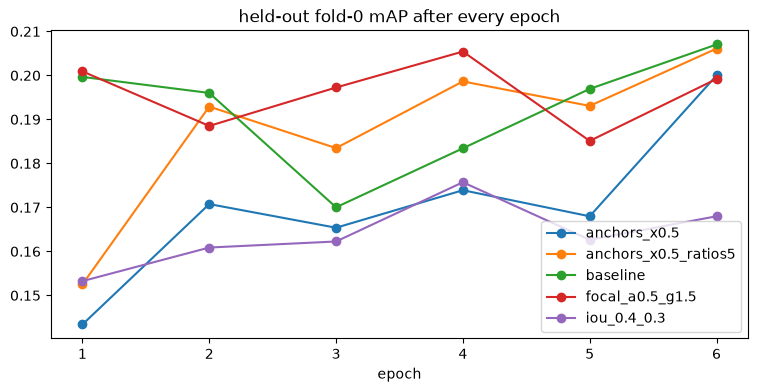

In [ ]:
curves = pd.DataFrame({name: [epoch['mAP'] for epoch in r['history']] for name, r in fold0_results.items()},
                      index=pd.Index(range(1, 7), name='epoch'))
display(curves.round(4))
curves.plot(marker='o', figsize=(9, 4), title='held-out fold-0 mAP after every epoch')
plt.show()

## Five folds: baseline and the tuned RetinaNet runs vs the tuned two-stage detector

In [ ]:
retina_files = sorted(TASK_DIR.glob('five_fold_results*.csv'))
retina_runs = pd.concat([pd.read_csv(f) for f in retina_files], ignore_index=True)
print('RetinaNet configurations:', sorted(retina_runs.config.unique()))

RetinaNet configurations: ['anchors_x0.5', 'anchors_x0.5_ratios5', 'baseline', 'focal_a0.5_g1.5', 'iou_0.4_0.3']


In [ ]:
FASTER_V1 = 'Faster R-CNN v1 lr_scheduler (tuned)'
faster_dir = ROOT / 'faster_rcnn'
faster_official = pd.read_csv(faster_dir / 'official_val_folds.csv')

faster_rows = []
for fold in range(5):
    result = json.loads((faster_dir / f'lr_scheduler/fold{fold}/result.json').read_text())
    official = faster_official.query('run == "lr_scheduler" and fold == @fold').iloc[0]
    faster_rows.append(dict(config=FASTER_V1, fold=fold, **{m: result['metrics'][m] for m in METRICS},
                            ms_per_img=result['ms_per_img'], official_mAP=official.mAP, official_AP50=official.AP50,
                            official_AP75=official.AP75, official_APs=official.APs))
faster_v1 = pd.DataFrame(faster_rows)

In [ ]:
all_runs = pd.concat([retina_runs, faster_v1], ignore_index=True)
summary_columns = METRICS + ['official_mAP', 'official_AP50', 'official_AP75', 'official_APs', 'ms_per_img']
summary = all_runs.groupby('config')[summary_columns].mean()

faster_v2 = pd.read_csv(ROOT / 'faster_rcnn/faster_rcnn_v2/v2_lr_scheduler_scale_aug_5fold.csv')
summary.loc['Faster R-CNN v2 + scale aug (extension)', ['mAP', 'official_mAP']] = [faster_v2.cv_mAP.mean(), faster_v2.official_mAP.mean()]
display(summary.round(4))

,mAP,AP50,AP75,APs,APm,APl,AR,official_mAP,official_AP50,official_AP75,official_APs,ms_per_img
config,,,,,,,,,,,,
Faster R-CNN v1 lr_scheduler (tuned),0.2110,0.4137,0.1925,0.0757,0.1981,0.3856,0.3450,0.1909,0.3937,0.1629,0.0879,25.7080
anchors_x0.5,0.1772,0.3699,0.1484,0.0657,0.1677,0.3162,0.3406,0.1593,0.3429,0.1286,0.0615,28.9611
anchors_x0.5_ratios5,0.1797,0.3688,0.1549,0.0669,0.1743,0.3212,0.3326,0.1557,0.3358,0.1251,0.0620,44.3383
baseline,0.1787,0.3423,0.1683,0.0589,0.1649,0.3395,0.2951,0.1483,0.2944,0.1327,0.0632,30.2327
focal_a0.5_g1.5,0.1789,0.3480,0.1629,0.0544,0.1687,0.3359,0.2938,0.1523,0.3017,0.1378,0.0635,30.1765
iou_0.4_0.3,0.1475,0.2785,0.1413,0.0323,0.1315,0.3007,0.2354,0.1238,0.2412,0.1144,0.0424,27.0186
Faster R-CNN v2 + scale aug (extension),0.2437,NaN,NaN,NaN,NaN,NaN,NaN,0.2219,NaN,NaN,NaN,NaN


In [ ]:
map_per_fold = all_runs.pivot_table(index='fold', columns='config', values='mAP')
display(map_per_fold.round(4))

config,Faster R-CNN v1 lr_scheduler (tuned),anchors_x0.5,anchors_x0.5_ratios5,baseline,focal_a0.5_g1.5,iou_0.4_0.3
fold,,,,,,
0,0.2377,0.2000,0.2061,0.2070,0.2054,0.1757
1,0.2208,0.1914,0.1967,0.1923,0.2033,0.1538
2,0.2380,0.1950,0.1916,0.1935,0.1915,0.1592
3,0.2015,0.1629,0.1689,0.1651,0.1630,0.1404
4,0.1571,0.1366,0.1351,0.1356,0.1314,0.1082


In [ ]:
def compare(config, reference):
    difference = map_per_fold[config] - map_per_fold[reference]
    print(f'{config} - {reference}: mean {difference.mean():+.4f}, folds better {int((difference > 0).sum())}/5')

for config in map_per_fold.columns:
    if config != FASTER_V1:
        compare(config, FASTER_V1)
print()
for config in sorted(retina_runs.config.unique()):
    if config != 'baseline':
        compare(config, 'baseline')

anchors_x0.5 - Faster R-CNN v1 lr_scheduler (tuned): mean -0.0338, folds better 0/5
anchors_x0.5_ratios5 - Faster R-CNN v1 lr_scheduler (tuned): mean -0.0313, folds better 0/5
baseline - Faster R-CNN v1 lr_scheduler (tuned): mean -0.0323, folds better 0/5
focal_a0.5_g1.5 - Faster R-CNN v1 lr_scheduler (tuned): mean -0.0321, folds better 0/5
iou_0.4_0.3 - Faster R-CNN v1 lr_scheduler (tuned): mean -0.0635, folds better 0/5

anchors_x0.5 - baseline: mean -0.0015, folds better 2/5
anchors_x0.5_ratios5 - baseline: mean +0.0010, folds better 2/5
focal_a0.5_g1.5 - baseline: mean +0.0002, folds better 1/5
iou_0.4_0.3 - baseline: mean -0.0312, folds better 0/5


In [ ]:
def per_class_official(config):
    folds = [json.loads((TASK_DIR / 'runs' / config / f'fold{k}/official_val.json').read_text())['metrics']['per_class']
             for k in range(5)]
    return pd.DataFrame(folds).mean()

per_class = pd.DataFrame({config: per_class_official(config) for config in sorted(retina_runs.config.unique())})
print('per-class AP on the official validation set (mean of the 5 fold checkpoints)')
display(per_class.round(4))

per-class AP on the official validation set (mean of the 5 fold checkpoints)


,anchors_x0.5,anchors_x0.5_ratios5,baseline,focal_a0.5_g1.5,iou_0.4_0.3
person,0.2128,0.2125,0.2140,0.2161,0.1629
bicycle,0.1682,0.1595,0.1470,0.1295,0.0797
car,0.3306,0.3322,0.3293,0.3326,0.2744
van,0.1618,0.1679,0.1497,0.1573,0.1520
truck,0.1187,0.0998,0.1137,0.1334,0.1186
tricycle,0.1614,0.1506,0.1484,0.1578,0.1345
bus,0.0351,0.0369,0.0182,0.0219,0.0275
motor,0.0860,0.0863,0.0662,0.0695,0.0405


In [ ]:
display(pd.read_csv(TASK_DIR / 'ablation.csv').round(4))

,config,fold,best_epoch,last_epoch_mAP,mAP,AP50,AP75,APs,APm,APl,AR
0,baseline,1,6,0.1923,0.1923,0.3720,0.1777,0.0860,0.1814,0.2866,0.3261
1,ablation_coco_no_ignore,1,6,0.1914,0.1914,0.3693,0.1769,0.0730,0.1755,0.2986,0.3214
2,ablation_imagenet_no_ignore,1,6,0.1975,0.1975,0.3925,0.1802,0.0594,0.1721,0.3131,0.3378


## Error analysis on the official validation set


In [ ]:
ERRORS_DIR = TASK_DIR / 'analysis'
ap_by_iou = pd.read_csv(ERRORS_DIR / 'ap_by_iou.csv').drop(columns='fold').groupby('model').mean()
ap_columns = [column for column in ap_by_iou.columns if column.startswith('AP@')]
class_columns = [column for column in ap_by_iou.columns if column.startswith('class ')]
display(ap_by_iou[ap_columns].round(4))

,AP@0.50,AP@0.55,AP@0.60,AP@0.65,AP@0.70,AP@0.75,AP@0.80,AP@0.85,AP@0.90,AP@0.95
model,,,,,,,,,,
Faster R-CNN v1,0.3937,0.3636,0.3256,0.2781,0.2228,0.1629,0.1023,0.0479,0.0110,0.0008
Faster R-CNN v2 + scale aug,0.4466,0.4167,0.3769,0.3263,0.2639,0.1950,0.1204,0.0573,0.0145,0.0012
RetinaNet baseline,0.2944,0.2750,0.2501,0.2176,0.1783,0.1327,0.0845,0.0405,0.0096,0.0004


In [ ]:
print('per-class AP (all models, official validation, single checkpoints)')
display(ap_by_iou[class_columns].T.round(4))

per-class AP (all models, official validation, single checkpoints)


model,Faster R-CNN v1,Faster R-CNN v2 + scale aug,RetinaNet baseline
class person,0.2484,0.2710,0.2140
class bicycle,0.1646,0.2223,0.1470
class car,0.3641,0.3811,0.3293
class van,0.2231,0.2458,0.1497
class truck,0.2209,0.2635,0.1137
class tricycle,0.1976,0.2184,0.1484
class bus,0.0073,0.0535,0.0182
class motor,0.1011,0.1195,0.0662


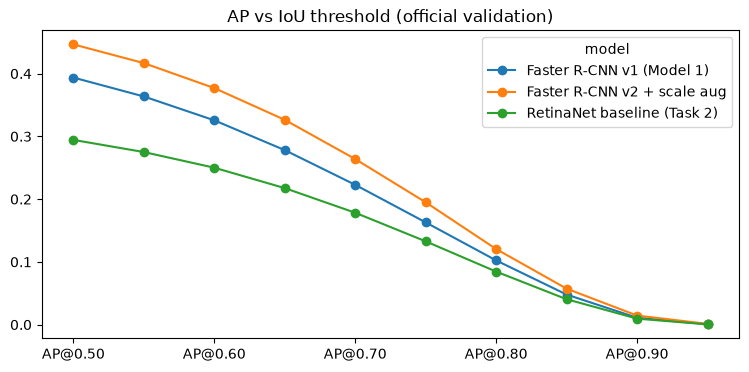

In [ ]:
ap_by_iou[ap_columns].T.plot(marker='o', figsize=(9, 4), title='AP vs IoU threshold (official validation)')
plt.show()

In [ ]:
error_breakdown = pd.read_csv(ERRORS_DIR / 'error_breakdown.csv').drop(columns='fold')
display(error_breakdown.groupby('model').mean().round(4))

,confident_detections,true positive,background (IoU < 0.1),class confusion (IoU >= 0.5),inside ignore region,"localisation (same class, IoU 0.1-0.5)",duplicate
model,,,,,,,
Faster R-CNN v1,120135.8,0.5456,0.1592,0.1002,0.1077,0.0793,0.0080
Faster R-CNN v2 + scale aug,124716.0,0.5616,0.1751,0.0948,0.0910,0.0717,0.0058
RetinaNet baseline,110485.6,0.5220,0.1476,0.1123,0.0975,0.1019,0.0187


In [ ]:
misses = pd.read_csv(ERRORS_DIR / 'misses.csv').drop(columns='fold')
display(misses.groupby(['model', 'objects']).mean().round(4))

n  missed_all_scores  missed_score_ge_0_3
model                       objects                                                  
Faster R-CNN v1   all      114132.0             0.3143               0.4162
                            large     12865.0             0.0523               0.1750
                            medium    79357.0             0.3131               0.4108
                            small     21910.0             0.4725               0.5776
Faster R-CNN v2 + scale aug all      114132.0             0.2701               0.3811
                            large     12865.0             0.0349               0.1534
                            medium    79357.0             0.2659               0.3753
                            small     21910.0             0.4232               0.5360
RetinaNet baseline all      114132.0             0.4208               0.4868
                            large     12865.0             0.0629               0.2102
                            medium    79357.0             0.4256               0.4817
                            small     21910.0             0.6137               0.6680

uav0000117_02622_v_00136.png


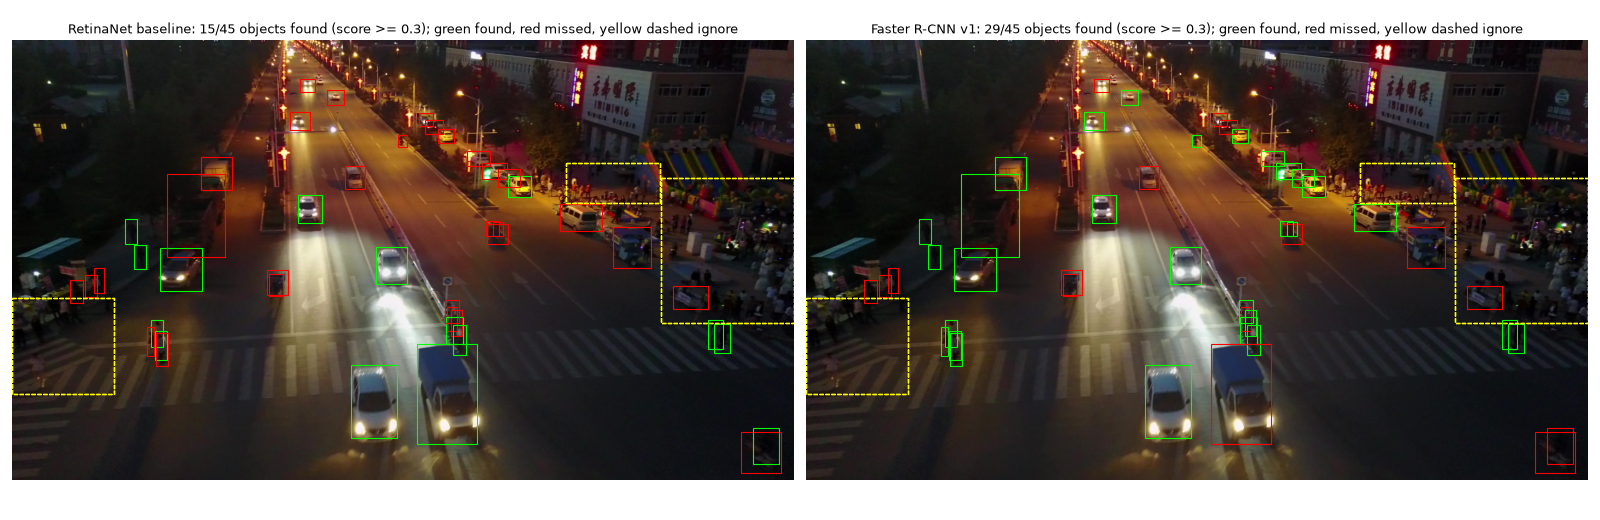

uav0000137_00458_v_00085.png


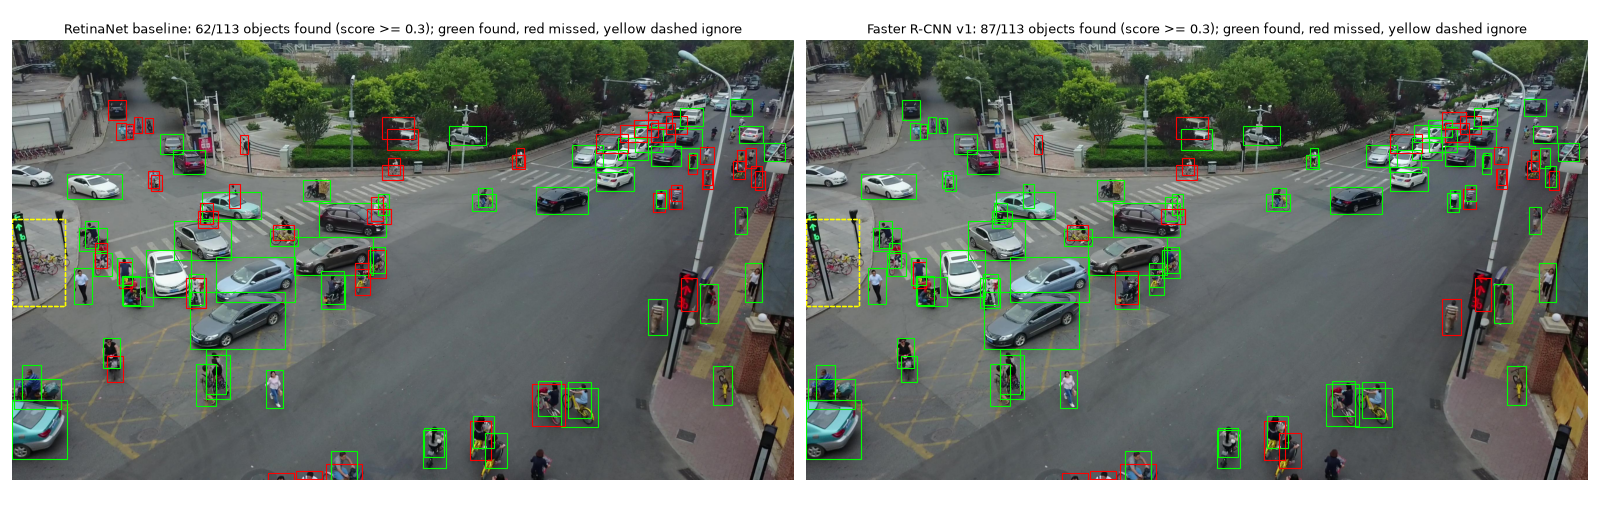

uav0000182_00000_v_00241.png


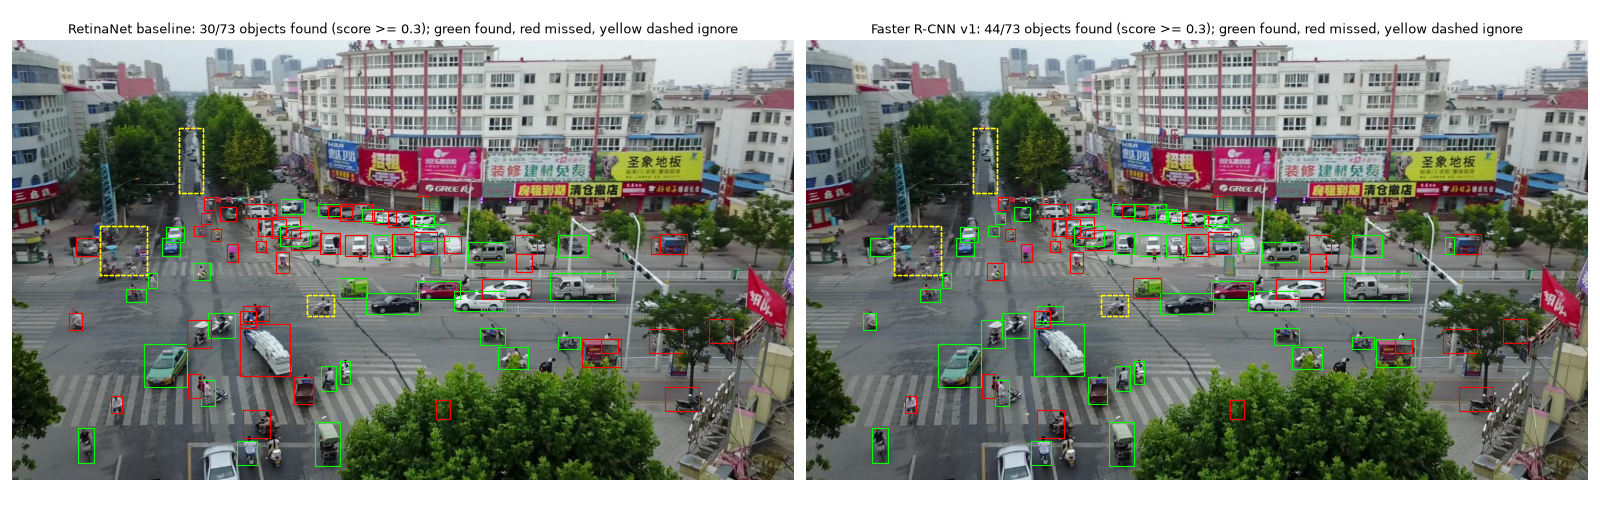

uav0000339_00001_v_00068.png


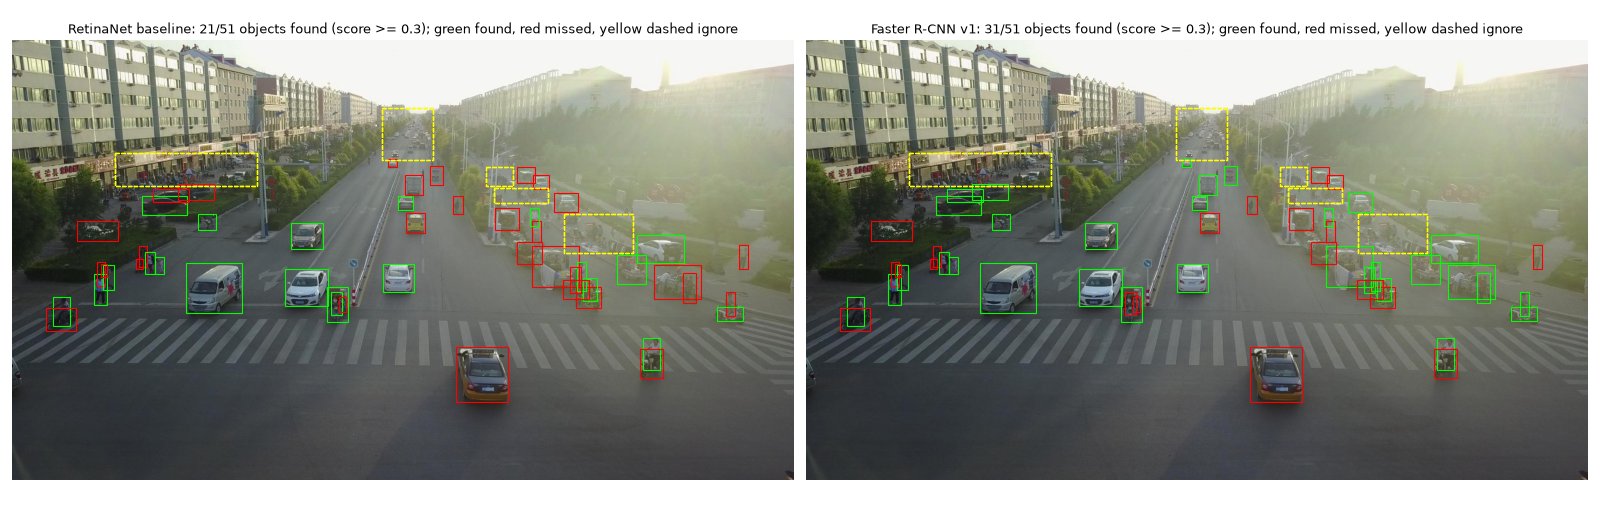

In [ ]:
for image_file in sorted((ERRORS_DIR / 'failure_cases').glob('*.png')):
    print(image_file.name)
    display(Image(filename=str(image_file)))